# Program Pengujian - Jaringan Saraf Tiruan Back Propagation

Alur: (1) unggah file bobot `bobot.npz` hasil training, (2) unggah **1 gambar**, (3) hitung propagasi maju (*application procedure*, Fausett hlm. 299-300), (4) tampilkan apakah gambar berhasil dikenali.

**Di laptop:** letakkan `pengujian.ipynb` satu folder dengan `bobot.npz` (butuh `numpy`, `Pillow`, `matplotlib`, dan `opencv-python`). Saat sel "Unggah 1 gambar" dijalankan, muncul **jendela pilih file**: pilih gambar apa pun dari laptop Anda (`.jpg`, `.png`, dan sebagainya). Kalau jendela tidak bisa dibuka, program meminta path file lewat kotak input. Anda juga bisa mengisi `BERKAS_GAMBAR` di sel pertama dengan path gambar agar tidak perlu memilih. Di Google Colab, unggah file saat diminta.

Gunakan gambar yang **tidak ikut dilatih**, yaitu `img51.jpg` sampai `img65.jpg` pada tiap folder kelas di `dataset/` (satu tingkat di atas folder ini) dan foto-foto pada folder `gambar_uji/` (satu tingkat di atas folder ini) (5 foto per kelas dari bagian `validation` repositori, belum pernah dilihat jaringan) (atau foto lain; foto apa pun otomatis di-preprocessing seperti saat training; sebaiknya satu objek utama di dalam bingkai dengan latar yang tidak terlalu ramai, karena objek dipisahkan dari latar dengan GrabCut). Notasi variabel sama dengan notebook training (`x`, `z_in`, `z`, `y_in`, `y`, `v`, `v_0`, `w`, `w_0`, `f`).

In [1]:
import io
import os
import numpy as np
import cv2
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

try:
    from google.colab import files
    DI_COLAB = True
except ImportError:      # dijalankan di komputer sendiri
    DI_COLAB = False

BERKAS_BOBOT = "bobot.npz"   # di laptop: file bobot dari training (satu folder dengan notebook ini)
BERKAS_GAMBAR = None         # None -> muncul jendela "pilih file" saat sel gambar dijalankan.
                             # Boleh diisi path, mis. "gambar_uji/kelas1_tshirt/uji1.jpg"

ambang = 0.5     # nilai output terbesar di bawah ambang -> tidak dikenali


def pilih_file_lokal(judul, tipe):
    # Di laptop: buka jendela pilih file (tkinter). Bila tidak tersedia, minta path lewat input().
    try:
        import tkinter as tk
        from tkinter import filedialog
        jendela = tk.Tk()
        jendela.withdraw()
        jendela.attributes("-topmost", True)
        path = filedialog.askopenfilename(title=judul, filetypes=tipe)
        jendela.destroy()
    except Exception:
        path = input(f"{judul} - ketik atau tempel path file: ")
    path = path.strip().strip("'").strip('"')   # buang tanda kutip bila path ditempel dengan kutip
    if not path:
        raise FileNotFoundError("Tidak ada file yang dipilih.")
    return path

## 1. Baca file bobot

In [2]:
if DI_COLAB:
    print("Unggah bobot.npz")
    unggah = files.upload()
    BERKAS_BOBOT = list(unggah.keys())[0]

if not DI_COLAB and not os.path.exists(BERKAS_BOBOT):
    BERKAS_BOBOT = pilih_file_lokal("Pilih file bobot (bobot.npz)", [("Bobot", "*.npz")])

bobot = np.load(BERKAS_BOBOT)
v, v_0, w, w_0 = bobot["v"], bobot["v_0"], bobot["w"], bobot["w_0"]
UKURAN = tuple(int(u) for u in bobot["ukuran"])
NAMA_KELAS = [str(k) for k in bobot["nama_kelas"]]
n, p = v.shape
m = w.shape[1]
print(f"Bobot dibaca: n={n} node input, p={p} node hidden, m={m} node output, ukuran gambar={UKURAN}")

Bobot dibaca: n=10000 node input, p=100 node hidden, m=3 node output, ukuran gambar=(100, 100)


## 2. Unggah / pilih 1 gambar

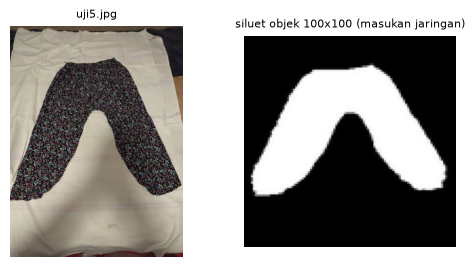

In [3]:
if DI_COLAB:
    print("Unggah 1 gambar uji")
    unggah = files.upload()
    nama_berkas = list(unggah.keys())[0]
    gambar = Image.open(io.BytesIO(unggah[nama_berkas]))
else:
    if BERKAS_GAMBAR is None:                 # pilih gambar sendiri dari laptop
        BERKAS_GAMBAR = pilih_file_lokal(
            "Pilih 1 gambar uji",
            [("Gambar", "*.jpg *.jpeg *.png *.bmp *.webp"), ("Semua file", "*.*")])
    nama_berkas = os.path.basename(BERKAS_GAMBAR)
    gambar = Image.open(BERKAS_GAMBAR)

gambar = ImageOps.exif_transpose(gambar)      # foto dari ponsel: putar sesuai orientasi kamera

# --- Preprocessing: pisahkan objek dari latar (GrabCut, OpenCV), lalu siluet 100 x 100 ---
def siluet_objek(gambar):
    # Segmentasi GrabCut dengan bingkai awal 92% bagian tengah gambar (objek diasumsikan di dalam bingkai).
    rgb = np.asarray(gambar.convert("RGB"))
    tinggi, lebar = rgb.shape[:2]
    skala = 200 / max(tinggi, lebar)                                    # GrabCut dijalankan pada gambar kecil
    kecil = cv2.resize(rgb, (int(lebar * skala), int(tinggi * skala)), interpolation=cv2.INTER_AREA)
    bgr = kecil[:, :, ::-1].copy()
    h, w = bgr.shape[:2]
    bingkai = (int(w * 0.04), int(h * 0.04), int(w * 0.92), int(h * 0.92))
    topeng = np.zeros((h, w), np.uint8)
    model_latar, model_objek = np.zeros((1, 65)), np.zeros((1, 65))
    cv2.setRNGSeed(0)                                                   # hasil sama pada setiap pemanggilan
    cv2.grabCut(bgr, topeng, bingkai, model_latar, model_objek, 5, cv2.GC_INIT_WITH_RECT)
    return (topeng == cv2.GC_FGD) | (topeng == cv2.GC_PR_FGD)           # True = objek, False = latar

def praproses(gambar):
    objek = siluet_objek(gambar)                                        # 1. pisahkan objek dari latar
    siluet = Image.fromarray((objek * 255).astype(np.uint8))            # 2. siluet: objek = 255, latar = 0 (citra 8-bit)
    siluet = siluet.resize((UKURAN[1], UKURAN[0]), Image.LANCZOS)       # 3. samakan ukuran ke 100 x 100
    x = np.asarray(siluet, dtype=np.float64).flatten() / 255.0          # 4. ratakan + 5. normalisasi 0..1
    assert x.shape == (n,)
    return x, siluet, objek.mean()

# Preprocessing identik dengan training
x, siluet, bagian_objek = praproses(gambar)
if bagian_objek < 0.02:
    print("PERINGATAN: objek hampir tidak terdeteksi. Gunakan foto dengan satu objek utama di dalam bingkai.")

fig, sumbu = plt.subplots(1, 2, figsize=(6, 3))
sumbu[0].imshow(gambar); sumbu[0].set_title(nama_berkas, fontsize=8)
sumbu[1].imshow(siluet, cmap="gray"); sumbu[1].set_title("siluet objek 100x100 (masukan jaringan)", fontsize=8)
for a in sumbu: a.axis("off")
plt.show()

## 3. Propagasi maju dan hasil pengenalan

In [4]:
def f(x):
    return 1.0 / (1.0 + np.exp(-x))

# Application procedure (hlm. 299-300)
z_in = v_0 + x @ v          # Langkah 3: z_in_j = v_0j + sum_i x_i v_ij
z = f(z_in)                 #            z_j = f(z_in_j)
y_in = w_0 + z @ w          # Langkah 4: y_in_k = w_0k + sum_j z_j w_jk
y = f(y_in)                 #            y_k = f(y_in_k)

k = int(np.argmax(y))
print("Keluaran jaringan:")
for i in range(m):
    print(f"  Y{i + 1} = {y[i]:.4f}   ({NAMA_KELAS[i]})")
print()
if y[k] >= ambang:
    print(f"HASIL: DIKENALI sebagai kelas {k + 1} - {NAMA_KELAS[k]} (Y{k + 1} = {y[k]:.4f})")
else:
    print(f"HASIL: TIDAK DIKENALI (nilai output terbesar {y[k]:.4f} < ambang {ambang})")

Keluaran jaringan:
  Y1 = 0.0005   (T-shirt)
  Y2 = 0.9678   (Pants (celana))
  Y3 = 0.4210   (Shoes (sepatu))

HASIL: DIKENALI sebagai kelas 2 - Pants (celana) (Y2 = 0.9678)


## Sumber dataset

Gambar pada folder `dataset/` berasal dari **clothing-dataset-small** (Alexey Grigorev), bukan dikumpulkan sendiri.

* **Repositori:** https://github.com/alexeygrigorev/clothing-dataset-small
* **Lisensi:** Creative Commons Zero v1.0 (CC0 1.0). README repositori: "This dataset can be freely used for any purpose."
* **Yang dipakai:** foto berwarna (JPEG, sekitar 400 x 533 piksel) dari tiga dari sepuluh kelas: `t-shirt`, `pants`, dan `shoes`. Tiap kelas 65 foto: 50 diambil acak dari folder `train` repositori (25 dengan `random.seed(2026)` dan 25 tambahan dengan `random.seed(2027)`) dan 15 dari folder `test`. Foto tidak diubah; `img01`-`img50` dipakai melatih dan `img51`-`img65` untuk uji. Pemetaan nama berkas ke berkas asli ada di `dataset/sumber_gambar.csv`.
* **Folder `gambar_uji/`** (khusus pengujian): 5 foto tambahan per kelas yang diambil acak (`random.seed(2028)`) dari folder `validation` repositori yang sama. Foto ini tidak termasuk di `dataset/` sehingga tidak pernah dilihat jaringan. Pemetaan ke berkas asli ada di `gambar_uji/sumber_gambar.csv`.
* **Preprocessing** (pemisahan objek dengan GrabCut dan ubah ukuran ke 100 x 100) dilakukan oleh program, bukan pada berkas dataset.